In [1]:
!pip install kaggle
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"ashwin832","key":"07a3a266801a2d58e742ab9d343d53bf"}'}

In [2]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [3]:
!kaggle competitions download -c dogs-vs-cats

 98% 792M/812M [00:10<00:00, 173MB/s]
100% 812M/812M [00:10<00:00, 80.2MB/s]


In [5]:
!unzip -qq dogs-vs-cats.zip -d dataset

In [6]:
!unzip -q dataset/train.zip -d dataset

In [9]:
import os
import cv2
import numpy as np

def load_images(folder,limit=25000):
  images=[]
  labels=[]
  for index,filename in enumerate(os.listdir(folder)):
    if index>=limit:
      break
    image_path=os.path.join(folder,filename)
    img=cv2.imread(image_path,cv2.IMREAD_GRAYSCALE)
    if img is not None:
      label = 0 if 'cat' in filename else 1
      img=cv2.resize(img,(64,64))
      images.append(img.flatten())
      labels.append(label)
  return np.array(images),np.array(labels)

In [10]:
X,Y=load_images('dataset/train',limit=25000)

In [11]:
X.shape

(25000, 4096)

In [13]:
import matplotlib.pyplot as plt

def show_image(img,labels,no_of_images):
  plt.figure(figsize=(10,5))
  for i in range(no_of_images):
    plt.subplot(1,no_of_images,i+1)
    plt.imshow(img[i].reshape(64,64),cmap='gray')
    plt.title('Dog' if labels[i] == 1 else 'Cat')
    plt.axis('off')
  plt.show()

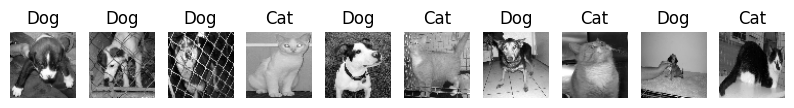

In [17]:
show_image(X,Y,10)

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

In [19]:
X_train_val,X_test,Y_train_val,Y_test=train_test_split(X,Y,test_size=0.2, random_state=42)

In [20]:
print(X_train_val.shape)
print(X_test.shape)
print(Y_train_val.shape)
print(Y_test.shape)

(20000, 4096)
(5000, 4096)
(20000,)
(5000,)


In [29]:
model=XGBClassifier()

In [30]:
model.fit(X_train_val,Y_train_val)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [31]:
train_data_prediction=model.predict(X_train_val)
train_data_accuracy=accuracy_score(Y_train_val,train_data_prediction)
print('Accuracy Score :',train_data_accuracy)

Accuracy Score : 0.994


In [32]:
test_data_prediction=model.predict(X_test)
test_data_accuracy=accuracy_score(Y_test,test_data_prediction)
print('Accuracy Score :',test_data_accuracy)

Accuracy Score : 0.6554
